[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIforPhilanthropy/eduall/blob/main/protocols/agentic_mimicking_protocols/TraditionalML/3_Gower/Gower_Protocol.ipynb)

# EduAll Foundation — Grant Call 2026
## Group Project Report: Traditional Machine Learning — Gower Distance to a Priority Profile

**Protocol:** `protocols/humaAI_Machine_Learning.pdf` — Human-AI condition, Approach 1 of 3 (traditional ML).
**Modeling path chosen:** example 3 of the protocol, *Gower distance on mixed data → distance to a declared reference profile*.
**Group:** Group ML-3, four students (A, B, C, D).
**Input data:** `data/EduAll_500_Applications_Dataset.csv` and the 500 application files in
`data/individual_applications/`.

We describe, feature by feature, the applicant the call most wants to reach (our *reference profile*), measure every applicant's weighted Gower distance to that profile across numeric and categorical variables, and fund in order of closeness. Clustering on the same distance shows us the structure of the pool.

This notebook **is** our project report. It follows the protocol's four steps:

1. **Anchor the model's objective** — from the mission statement and the grant call: the 7 eligibility
   (hard, pass/fail) and 5 priority (soft, scored) criteria, plus the nuances we add as a group.
2. **Choose and execute a modeling path** — and why we chose it.
3. **Build and validate** — features used and excluded, fitting, the validation criterion, seed-sensitivity
   runs, and a human review of the model's output against the underlying records.
4. **Documentation and reproducibility** — full specification, which decisions are the model's and which
   are ours, the final funding list, and the output files `decision_progression.csv` and
   `final_allocation.csv`.

In [ ]:
# --- Get the data -------------------------------------------------------------------------------
# On Google Colab this cell downloads the course repository (data + notebooks) from GitHub and moves into this
# notebook's folder, so every data path below works as on the course computers. Locally it does nothing.
import os, pathlib, subprocess
REPO_URL = "https://github.com/AIforPhilanthropy/eduall.git"
NOTEBOOK_DIR = "protocols/agentic_mimicking_protocols/TraditionalML/3_Gower"          # this notebook's folder inside the repository
here = pathlib.Path.cwd()
if not any((p / "data" / "EduAll_500_Applications_Dataset.csv").exists() for p in [here, *here.parents]):
    if not pathlib.Path("/content/eduall").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/eduall"], check=True)
    os.chdir(pathlib.Path("/content/eduall") / NOTEBOOK_DIR)
print("working directory:", os.getcwd())

---
## Step 1 — Anchor the model's objective

*Budget: ~13.0h for a 4-student group.*

We read the foundation's **Organization Profile** (mission and values) and the **Grant Call 2026**
(eligibility, ineligible categories, priority considerations, weighted evaluation criteria, award rules),
and the FAQ where the call refers to it.

**Mission (Organization Profile):** *"Our focus is not on academic excellence or competition, but rather on
identifying students with genuine financial need and providing them with the means to pursue their
studies."*

### 1.1 Eligibility criteria (hard, pass/fail, n = 7)

These are the call's seven *Primary Eligibility Requirements*. The last column says how we check each one in
the data, including our group's decisions where the call leaves room for interpretation.

| # | Criterion (Grant Call) | How we check it | Our decision |
|---|---|---|---|
| H1 | Non-Swiss citizen | `country_origin` | All 500 applicants are international by construction: pass. |
| H2 | Legally residing in Switzerland (valid permit B, C, F, S...; pending permits case by case) | `residency_permit`, plus the ineligible category *"Permit C and significant family financial resources"* | Permits B, C, F, S pass; Pending permits are eligible and *conditional*. Permit C with a supporting household of CHF 5,000/month or more fails. A settled (C) permit already gives access to cantonal scholarships, so we read "significant resources" strictly. |
| H3 | Accepted or enrolled at an accredited Swiss institution | `university` | All listed institutions are accredited: pass. |
| H4 | Documented genuine financial need | expected 2027/28 shortfall `monthly_expenses − family support − expected personal income`, for the months of study inside the grant period (Sep 2027 – Aug 2028) | Pass if the expected 2027/28 shortfall is positive in the grant period (months from the completion date in the file). |
| H5 | Satisfactory academic standing, normally GPA ≥ 2.5 (exceptions if the reasons are explained) | `gpa`, `academic_standing` | GPA below 2.5 does not exclude. The call allows exceptions, and our approach handles academic standing as a *distance*: a low GPA moves the applicant away from the reference profile instead of off the list. |
| H6 | Bachelor's, master's or doctoral degree, full-time or part-time | `study_level`, `study_mode` | All applicants qualify: pass. |
| H7 | No outstanding legal or immigration issues | not observable in the data | Assumed satisfied; pending permits are handled in H2. |


### 1.2 Priority criteria (soft, scored, n = 5)

| # | Criterion (Grant Call weight) | What it means for us | Variables |
|---|---|---|---|
| S1 | Financial need (40%) | Shortfall ratio, household income, and absence of savings and other scholarships (the call's "lack of alternative funding"). | `shortfall_ratio`, `family_household_income_chf`, `savings_chf`, `external_scholarship_amount_chf` |
| S2 | Academic motivation & potential (25%) | Solid standing and progress towards the degree; *not* top grades (FAQ Q11). | `gpa`, `progress` |
| S3 | Personal resilience & determination (20%) | Resilience factors declared and hardships faced. | `resil_count`, `risk_count` |
| S4 | Contribution to diversity (10%) | Low-income country, first generation. | `gni_tier` (categorical), `risk_first_generation` |
| S5 | Alignment with EduAll values (5%) | Community and volunteer commitment. | `resilience_community_engagement`, `resilience_volunteer_experience` |

The call also names **priority groups**: students from low-income countries (GNI per capita below USD 3,000,
`gni_tier == 1`), first-generation students, students from under-represented regions, and students
demonstrating exceptional resilience.


### 1.3 Nuances we add as a group

* **One profile, written down.** We want every funding decision to be explainable in one sentence: *"this applicant
  is closer to the profile the call describes than the next one"*. Gower distance makes this possible: it handles
  numbers and categories together, and every applicant's distance splits into one contribution per feature.
* **Savings.** Savings above one month of expenses (an emergency reserve) are counted, spread over the months until
  graduation; the grant-period share is deducted from the request.
* **Number of awards.** We aim for about **150 awards**, the middle of the call's 140–180 estimate. The award fraction
  is set to reach that number (Step 4).

❓ **Question for students:** writing down an explicit "ideal applicant" makes the value judgement transparent. Does
it also make it more contestable? Would you rather defend a profile or a weighted score in front of an applicant
who was not funded?

---
## Step 2 — Choose and execute a modeling path

*Budget: ~27.6h.*

We chose the protocol's **Gower-distance path** (unsupervised). Gower distance between two records is the
weighted average of per-feature distances: |x − y| / range for numeric features, 0 or 1 (match / no match) for
categorical ones. All per-feature distances lie between 0 and 1, so no feature dominates because of its unit.
We use it twice:

1. **Distance to a reference profile**: our ranking;
2. **Pairwise distances among eligible applicants**: hierarchical clustering, to see where the applicants closest to
   the profile sit in the pool.

The `gower` package is not part of our environment, so we implement the formula directly (about ten lines); the
function is shown below and is easy to check.

In [1]:
import pathlib, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.metrics import silhouette_score
from scipy.stats import spearmanr
SEED = 2026
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
# Data: works from the course folder (protocols/agentic_mimicking_protocols/TraditionalML/<approach>/)
# and on Google Colab (upload the CSV and individual_applications.zip when asked).
CANDIDATES = [pathlib.Path("../../../../data"), pathlib.Path("../../../data"), pathlib.Path("data"), pathlib.Path(".")]
DATA = next((b for b in CANDIDATES if (b / "EduAll_500_Applications_Dataset.csv").exists()), None)
if DATA is None:
    from google.colab import files            # only reached on Colab
    print("Upload EduAll_500_Applications_Dataset.csv and individual_applications.zip")
    files.upload()
    DATA = pathlib.Path(".")
APPS = DATA / "individual_applications"
if not APPS.exists() and (DATA / "individual_applications.zip").exists():
    with zipfile.ZipFile(DATA / "individual_applications.zip") as z:
        z.extractall(DATA)

df = pd.read_csv(DATA / "EduAll_500_Applications_Dataset.csv", keep_default_na=False).set_index("student_id", drop=False)
df.index.name = None
docs = {sid: (APPS / f"{sid}_application.md").read_text(encoding="utf-8") for sid in df.student_id}
print(df.shape, "| application files:", len(docs))

(500, 44) | application files: 500


In [3]:
# Quantities every approach needs, computed from the call's own rules
RISK = ["risk_first_generation", "risk_refugee_asylum", "risk_disability", "risk_housing_insecurity",
        "risk_family_emergency", "risk_language_barrier", "risk_parent_student", "risk_undocumented_status"]
RESIL = ["resilience_volunteer_experience", "resilience_work_experience", "resilience_leadership_role",
         "resilience_community_engagement", "resilience_overcame_adversity"]
CAP = {"Bachelor's": 8000, "Master's": 6500, "Doctoral": 5000}          # annual maximum by level
REQUIRED = {"Bachelor's": 40, "Master's": 12, "Doctoral": 12}             # courses per degree

# Expected completion is stated in each application form; we read it from the file.
MONTH = {"January": 1, "July": 7}
def completion(text):
    m = re.search(r"\*\*Expected Completion:\*\*\s*(January|July) (\d{4})", text)
    return (int(m.group(2)), MONTH[m.group(1)]) if m else (None, None)

df["completion_year"], df["completion_month"] = zip(*[completion(docs[s]) for s in df.student_id])
# months of study inside the grant period Sep 2027 - Aug 2028 (finish Jan 2028 -> 5, Jul 2028 -> 11, later -> 12)
grant_end = (2028, 8)
def months_in_grant(y, m):
    if y is None: return 12
    if (y, m) < (2027, 9): return 0
    if (y, m) >= grant_end: return 12
    return (y - 2027) * 12 + m - 9 + 1
df["months_in_grant"] = [months_in_grant(y, m) for y, m in zip(df.completion_year, df.completion_month)]
df["months_to_completion"] = [(y - 2026) * 12 + m - 9 + 1 for y, m in zip(df.completion_year, df.completion_month)]  # from Sep 2026

df["need_2027"] = (df.monthly_expenses_chf - df.family_income_chf - df.expected_personal_income_2027_chf).clip(lower=0)
df["shortfall_ratio"] = (df.need_2027 / df.monthly_expenses_chf).clip(0, 1)
df["risk_count"] = df[RISK].sum(axis=1)
df["resil_count"] = df[RESIL].sum(axis=1)
df["progress"] = (df.courses_completed / df.study_level.map(REQUIRED)).clip(0, 1)
df["cap_period"] = df.study_level.map(CAP) * df.months_in_grant / 12
print(df.months_in_grant.value_counts().sort_index().to_dict())

{5: 50, 11: 283, 12: 167}


In [4]:

PERMIT_C_LIMIT = 5000      # "significant family financial resources" for Permit C (our threshold)
df["H1"] = np.where(df.country_origin != "Switzerland", "pass", "fail")
df["H2"] = np.select([(df.residency_permit == "C") & (df.family_household_income_chf >= PERMIT_C_LIMIT),
                      df.residency_permit == "Pending"],
                     ["fail (Permit C, household >= CHF 5,000)", "conditional (permit pending)"], "pass")
df["H3"] = np.where(df.university.str.len() > 0, "pass", "fail")
df["H4"] = np.where((df.need_2027 > 0) & (df.months_in_grant > 0), "pass", "fail (no shortfall in grant period)")
df["H5"] = np.where(df.gpa >= 2.5, "pass", "pass (lower priority)")   # handled in the score
df["H6"] = np.where(df.study_level.isin(CAP) & df.study_mode.isin(["Full-time", "Part-time"]), "pass", "fail")
df["H7"] = "pass (assumed)"
HARD = ["H1", "H2", "H3", "H4", "H5", "H6", "H7"]
df["eligible"] = ~df[HARD].apply(lambda c: c.str.startswith("fail")).any(axis=1)
df["conditional"] = df[HARD].apply(lambda c: c.str.startswith("conditional")).any(axis=1)
summary = pd.DataFrame({h: df[h].value_counts() for h in HARD}).fillna(0).astype(int)
display(summary)
print(f"eligible: {df.eligible.sum()} of {len(df)} (of which conditional: {(df.eligible & df.conditional).sum()})")

,H1,H2,H3,H4,H5,H6,H7
conditional (permit pending),0,16,0,0,0,0,0
"fail (Permit C, household >= CHF 5,000)",0,37,0,0,0,0,0
fail (no shortfall in grant period),0,0,0,76,0,0,0
pass,500,447,500,424,419,500,0
pass (assumed),0,0,0,0,0,0,500
pass (lower priority),0,0,0,0,81,0,0


eligible: 401 of 500 (of which conditional: 16)


In [5]:
# Award request for the grant period: shortfall x months, minus other scholarships and savings, capped
# Savings: savings above one month of expenses are spread until graduation; the grant-period share is deducted
df["scholarship_period"] = df.external_scholarship_amount_chf * df.months_in_grant / 12
df["savings_counted"] = ((df.savings_chf - df.monthly_expenses_chf).clip(lower=0) * np.minimum(1, df.months_in_grant / df.months_to_completion)).round()
df["request"] = (df.need_2027 * df.months_in_grant - df.scholarship_period - df.savings_counted).clip(lower=0)
df["request"] = np.minimum(df.request, df.cap_period).round()
print(f"eligible applicants with a positive request: {(df.eligible & (df.request > 0)).sum()}; "
      f"their total request: CHF {df.loc[df.eligible, 'request'].sum():,.0f} vs budget CHF 500,000")

eligible applicants with a positive request: 387; their total request: CHF 2,105,550 vs budget CHF 500,000


---
## Step 3 — Build and validate

*Budget: ~81.2h.*

### 3.1 Features, weights and the reference profile

Each soft criterion's weight is split across its variables. **Excluded:** gender, age, country, university, field
of study, average grade (duplicates GPA), publications, application date. The reasons are the same as in Step 1:
these variables either carry no criterion or risk becoming proxies.

| Feature | Type | Weight | Reference value | Why |
|---|---|---|---|---|
| `shortfall_ratio` | numeric | 0.20 | max among eligible | need (S1) |
| `family_household_income_chf` | numeric | 0.10 | min among eligible | need (S1) |
| `savings_chf` | numeric | 0.05 | 0 | lack of alternatives (S1) |
| `external_scholarship_amount_chf` | numeric | 0.05 | 0 | lack of alternatives (S1) |
| `gpa` | numeric | 0.10 | 3.0 | standing, not excellence (S2) |
| `progress` | numeric | 0.15 | 1.0 (degree completed) | progress to degree (S2); *revised in 4.1* |
| `resil_count` | numeric | 0.10 | 5 | resilience (S3) |
| `risk_capped` (= min(risk_count, 4)) | numeric | 0.10 | 4 | hardship overcome (S3) |
| `gni_tier` | categorical | 0.06 | tier 1 | low-income country (S4) |
| `risk_first_generation` | categorical | 0.04 | 1 | first generation (S4) |
| `resilience_community_engagement` | categorical | 0.025 | 1 | values (S5) |
| `resilience_volunteer_experience` | categorical | 0.025 | 1 | values (S5) |

Weights sum to 1 and follow the call's 40/25/20/10/5.

In [6]:
df["risk_capped"] = df.risk_count.clip(upper=4)
df["progress_lvl"] = df.groupby("study_level").progress.rank(pct=True)     # used only in the revision (4.1)
NUM = {"shortfall_ratio": .20, "family_household_income_chf": .10, "savings_chf": .05, "external_scholarship_amount_chf": .05,
       "gpa": .10, "progress": .15, "resil_count": .10, "risk_capped": .10}
CAT = {"gni_tier": .06, "risk_first_generation": .04, "resilience_community_engagement": .025, "resilience_volunteer_experience": .025}
W = {**NUM, **CAT}
assert abs(sum(W.values()) - 1) < 1e-9
E = df[df.eligible].copy()
NUMERIC = list(NUM) + ["progress_lvl"]
RANGE = {c: E[c].max() - E[c].min() for c in NUMERIC}

def reference(gpa_ref):
    return {"shortfall_ratio": E.shortfall_ratio.max(), "family_household_income_chf": E.family_household_income_chf.min(),
            "savings_chf": 0, "external_scholarship_amount_chf": 0, "gpa": gpa_ref, "progress": 1.0, "resil_count": 5,
            "risk_capped": 4, "gni_tier": 1, "risk_first_generation": 1, "resilience_community_engagement": 1,
            "resilience_volunteer_experience": 1}

def gower_to(X, ref, w=W):
    """weighted Gower distance of every row of X to the profile ref; returns (distance, per-feature contributions)"""
    parts = {}
    for c in w:
        d = (X[c] - ref[c]).abs() / RANGE[c] if c in NUMERIC else (X[c] != ref[c]).astype(float)
        parts[c] = w[c] * d.clip(0, 1)
    parts = pd.DataFrame(parts)
    return parts.sum(axis=1) / sum(w.values()), parts

REF = reference(3.0)
E["gower_draft1"], CONTRIB = gower_to(E, REF)
pd.Series(REF, name="reference profile").to_frame().T

,shortfall_ratio,family_household_income_chf,savings_chf,external_scholarship_amount_chf,gpa,progress,resil_count,risk_capped,gni_tier,risk_first_generation,resilience_community_engagement,resilience_volunteer_experience
reference profile,0.977273,230.0,0.0,0.0,3.0,1.0,5.0,4.0,1.0,1.0,1.0,1.0


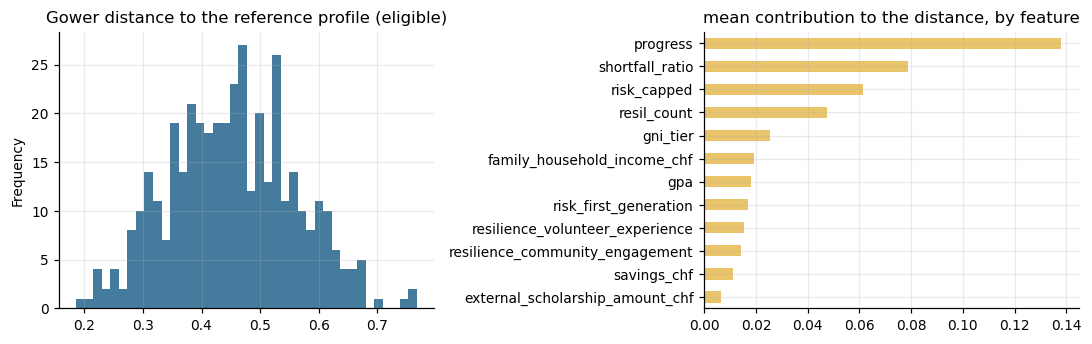

{'count': 401.0, 'mean': 0.453, 'std': 0.107, 'min': 0.187, '25%': 0.378, '50%': 0.453, '75%': 0.529, 'max': 0.767}


In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
E.gower_draft1.plot.hist(bins=40, ax=axs[0], color="#457b9d"); axs[0].set_title("Gower distance to the reference profile (eligible)")
CONTRIB.mean().sort_values().plot.barh(ax=axs[1], color="#e9c46a"); axs[1].set_title("mean contribution to the distance, by feature")
plt.tight_layout(); plt.show()
print(E.gower_draft1.describe().round(3).to_dict())

**What we see.** Distances to the profile range from 0.19 to 0.77 (median 0.45). Nobody is close to the reference: it combines every priority at once, and no real applicant does. The bar chart shows what *separates* applicants from the profile on average. One feature dominates: **`progress`** contributes on average 0.138 of its maximum possible 0.15, almost a third of the median distance. The next largest is the shortfall ratio (0.079). We come back to this in 3.4.

### 3.2 Structure of the pool: hierarchical clustering on pairwise Gower distance

The same weights and per-feature distances, applied to every pair of eligible applicants; average linkage; number of
clusters by silhouette (precomputed distance).

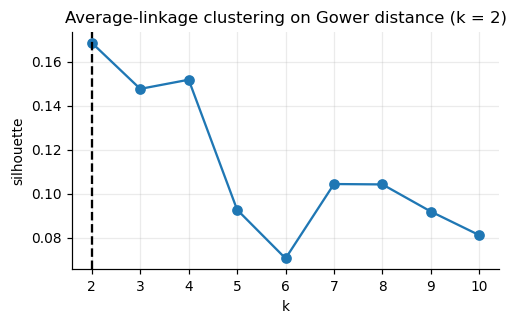

{2: 0.169, 3: 0.148, 4: 0.152, 5: 0.093, 6: 0.07, 7: 0.104, 8: 0.104, 9: 0.092, 10: 0.081}


,n,mean_distance,shortfall_ratio,household,tier1,first_gen,gpa,resil
gower_cluster,,,,,,,,
1,350,0.44,0.66,1130.0,61.71,0.53,3.03,2.59
2,51,0.52,0.22,4290.0,27.45,0.92,2.93,2.86


In [8]:
Xn = E[list(NUM)].to_numpy(float); Xc = E[list(CAT)].to_numpy(float)
wn = np.array(list(NUM.values())); wc = np.array(list(CAT.values())); rn = np.array([RANGE[c] for c in NUM])
D = (np.abs(Xn[:, None, :] - Xn[None, :, :]) / rn * wn).sum(-1) + ((Xc[:, None, :] != Xc[None, :, :]) * wc).sum(-1)
np.fill_diagonal(D, 0)
Z = linkage(squareform(D, checks=False), method="average")
sil = {k: silhouette_score(D, fcluster(Z, k, "maxclust"), metric="precomputed") for k in range(2, 11)}
K = max(sil, key=sil.get)
E["gower_cluster"] = fcluster(Z, K, "maxclust")
E["gower"] = E.gower_draft1          # placeholder for the summary below; replaced by the revised distance in 4.1
plt.figure(figsize=(5, 2.8)); plt.plot(list(sil), list(sil.values()), "o-"); plt.axvline(K, ls="--", c="k")
plt.xlabel("k"); plt.ylabel("silhouette"); plt.title(f"Average-linkage clustering on Gower distance (k = {K})"); plt.show()
print({k: round(v, 3) for k, v in sil.items()})
display(E.groupby("gower_cluster").agg(n=("gower", "size"), mean_distance=("gower", "mean"),
        shortfall_ratio=("shortfall_ratio", "median"), household=("family_household_income_chf", "median"),
        tier1=("gni_tier", lambda s: (s == 1).mean() * 100), first_gen=("risk_first_generation", "mean"),
        gpa=("gpa", "median"), resil=("resil_count", "mean")).sort_values("mean_distance").round(2))

**What we see.** The silhouette is highest at k = 2 (0.17), and the split is very uneven: 350 against 51. The small cluster consists of applicants with **low shortfall ratios (median 0.22) and high household incomes (median CHF 4,290)**, mostly first-generation (92%), and on average further from the profile (0.52 against 0.44). The pool therefore has no clear internal structure, apart from one group of better-resourced applicants. None of them would be reached by our funding line anyway. We use the clustering only as a description and not in the funding rule.

### 3.3 Sensitivity: weights and reference profile

Gower distance has no random seed. Its "seeds" are our own choices, so we perturb those instead:

* **Weights:** 30 random perturbations, each weight multiplied by a factor drawn uniformly from 0.75–1.25, then
  renormalised;
* **Reference:** GPA reference 4.0 instead of 3.0; uncapped risk count; household reference at the 10th
  percentile instead of the minimum.

For each variant we compare the ranking (Spearman) and the top-150 list (Jaccard index) with our final specification.

In [9]:
rng = np.random.default_rng(SEED)
base = E.gower_draft1
top150 = lambda s: set(s.nsmallest(150).index)
rows = []
for i in range(30):
    w = {c: v * rng.uniform(0.75, 1.25) for c, v in W.items()}
    g, _ = gower_to(E, REF, w)
    rows.append(("weights ±25%", spearmanr(base, g)[0], len(top150(base) & top150(g)) / len(top150(base) | top150(g))))
for name, ref in [("GPA reference 4.0", reference(4.0)), ("household ref = 10th pct", {**REF, "family_household_income_chf": E.family_household_income_chf.quantile(.1)})]:
    g, _ = gower_to(E, ref); rows.append((name, spearmanr(base, g)[0], len(top150(base) & top150(g)) / len(top150(base) | top150(g))))
E2 = E.assign(risk_capped=E.risk_count); RANGE_save = RANGE["risk_capped"]; RANGE["risk_capped"] = E.risk_count.max() - E.risk_count.min()
g, _ = gower_to(E2, {**REF, "risk_capped": E.risk_count.max()}); RANGE["risk_capped"] = RANGE_save
rows.append(("risk count uncapped", spearmanr(base, g)[0], len(top150(base) & top150(g)) / len(top150(base) | top150(g))))
sens = pd.DataFrame(rows, columns=["variant", "spearman", "jaccard_top150"])
display(sens.groupby("variant").agg(runs=("spearman", "size"), spearman_min=("spearman", "min"), spearman_mean=("spearman", "mean"),
        jaccard_min=("jaccard_top150", "min"), jaccard_mean=("jaccard_top150", "mean")).round(3))
g4, _ = gower_to(E, reference(4.0))
enter, leave = top150(g4) - top150(base), top150(base) - top150(g4)
print("GPA reference 4.0 instead of 3.0 -> GPA of those entering the top 150:", sorted(E.loc[list(enter), "gpa"]))
print("                                   GPA of those leaving the top 150: ", sorted(E.loc[list(leave), "gpa"]))

,runs,spearman_min,spearman_mean,jaccard_min,jaccard_mean
variant,,,,,
GPA reference 4.0,1,0.972,0.972,0.852,0.852
household ref = 10th pct,1,1.000,1.000,0.987,0.987
risk count uncapped,1,0.997,0.997,0.948,0.948
weights ±25%,30,0.988,0.995,0.887,0.937


GPA reference 4.0 instead of 3.0 -> GPA of those entering the top 150: [3.26, 3.29, 3.3, 3.42, 3.55, 3.61, 3.62, 3.69, 3.7, 3.77, 3.86, 4.0]
                                   GPA of those leaving the top 150:  [2.53, 2.56, 2.66, 2.74, 2.78, 2.81, 2.83, 2.86, 2.9, 2.96, 2.97, 2.97]


**What we see (B and C ran the variants).**

* **Weights ±25%:** the ranking is very stable (Spearman ≥ 0.988). Between 89% and 99% of the top-150 list stays the same (Jaccard 0.89–0.99). No single weight decision is pivotal.
* **Household reference** (minimum vs 10th percentile) and **uncapped risk count:** almost no effect.
* **GPA reference 4.0 instead of 3.0** is the largest change (Jaccard 0.85). It swaps 12 applicants. All of those entering have GPAs of 3.26 to 4.0, and all of those leaving have GPAs of 2.53 to 2.97. The "excellence or standing" choice therefore decides a dozen awards. We keep 3.0 because FAQ Q11 states that academic excellence is not a primary criterion.

❓ **Question for students:** with a reference of 3.0, an applicant with a GPA of 4.0 is exactly as far from the profile as one with 2.0. Is that a reasonable reading of "satisfactory academic standing", or does it penalise strong students for no reason the call gives?

### 3.4 Human review at the funding margin

Distances are never exactly equal, so the decisions that matter most are those at the **cut-off**. We read the files
of the three applicants just inside and the three just outside the expected top-150 line, and compare their
per-feature contributions.

In [10]:
E["gower_rank"] = E.gower_draft1.rank(method="first").astype(int)
margin = E[E.gower_rank.between(148, 153)].sort_values("gower_rank")
show_cols = ["gower_rank", "gower_draft1", "shortfall_ratio", "family_household_income_chf", "savings_chf", "gpa", "progress",
             "resil_count", "risk_count", "gni_tier", "risk_first_generation", "study_level"]
display(margin[show_cols].round(3))
display(CONTRIB.loc[margin.index].round(3).assign(total=lambda x: x.sum(axis=1)))
def excerpt(sid, n=600):
    t = docs[sid]; i = t.find("## Section 4")
    return re.sub(r"\s+", " ", t[i:].split("\n", 3)[-1])[:n]
for sid in margin.index:
    print(f"#{E.at[sid, 'gower_rank']} {sid}:", excerpt(sid), "...\n")

,gower_rank,gower_draft1,shortfall_ratio,family_household_income_chf,savings_chf,gpa,progress,resil_count,risk_count,gni_tier,risk_first_generation,study_level
STU000378,148,0.413,0.254,580,1129,2.66,0.150,3,3,1,1,Bachelor's
STU000402,149,0.415,0.920,620,6571,2.96,0.333,2,1,1,0,Master's
STU000413,150,0.417,0.967,270,9091,3.28,0.250,1,2,1,0,Master's
STU000375,151,0.417,0.775,1220,9353,2.72,0.250,2,4,2,1,Master's
STU000116,152,0.417,0.819,510,0,2.46,0.167,3,1,1,0,Master's
STU000361,153,0.418,0.731,550,0,2.15,0.475,2,1,1,0,Bachelor's


,shortfall_ratio,family_household_income_chf,savings_chf,external_scholarship_amount_chf,gpa,progress,resil_count,risk_capped,gni_tier,risk_first_generation,resilience_community_engagement,resilience_volunteer_experience,total
STU000378,0.148,0.004,0.004,0.0,0.017,0.150,0.04,0.025,0.00,0.00,0.000,0.025,0.413
STU000402,0.012,0.004,0.022,0.0,0.002,0.150,0.06,0.075,0.00,0.04,0.025,0.025,0.415
STU000413,0.002,0.000,0.030,0.0,0.014,0.150,0.08,0.050,0.00,0.04,0.025,0.025,0.416
STU000375,0.041,0.011,0.031,0.0,0.014,0.150,0.06,0.000,0.06,0.00,0.025,0.025,0.417
STU000116,0.032,0.003,0.000,0.0,0.027,0.150,0.04,0.075,0.00,0.04,0.025,0.025,0.417
STU000361,0.050,0.003,0.000,0.0,0.043,0.121,0.06,0.075,0.00,0.04,0.000,0.025,0.417


#148 STU000378:  I am in the second year of my Bachelor of Law at the University of Lucerne, which I study part-time, and I am applying to EduAll to be able to continue at a steady pace. My monthly expenses are CHF 2,123, including CHF 1,138 for a room and CHF 180 for tuition. I work about 13 hours a week as a Bengali and Hindi community interpreter for social services and schools, and earn CHF 1,453. My brother, a clerk in Rajshahi, gives me CHF 130 from the roughly CHF 580 the household has. My room is a temporary sublet that ends in November, and I have not yet found a permanent place. The gap is CHF 540 a ...

#149 STU000402:  - MSc Public Health, University of Zurich. Four semesters left. Ends July 2028. - Costs: CHF 1,871 (room CHF 693). - Support: CHF 150 from my brother, a customs officer in Lagos (household about CHF 620). - No job during thesis semester. - In May my brother's wife fell seriously ill; his budget for me will shrink. A grant would cover the last months. --- ## S

**Human review at the margin (each of us read one or two files).**

* **STU000378** (rank 148, inside the line) has a shortfall ratio of only **0.25**: a part-time law student who earns CHF 1,453 as a community interpreter. They are inside because the other features compensate (tier 1, first-generation, three risk factors). Their shortfall-ratio term alone (0.148) costs as much as the whole difference between ranks 148 and 153. Meanwhile **STU000116** (0.82, no savings, housing about to end) and **STU000361** (0.73, no savings) sit just *outside*.
* **STU000413** (rank 150) has CHF 9,091 in savings, which the file explains: the remainder of a scholarship for scholars at risk, plus the sale of a late father's books, used to cover a gap of CHF 2,354 a month. The savings term treats this as an alternative resource. Our savings rule is right to deduct only what exceeds one month's expenses.
* In the contribution table, **all six applicants have the same `progress` term, 0.150**: the maximum possible. The feature with the second-largest weight does not separate them at all.

In [11]:
# Follow-up to the margin review: how much does `progress` actually discriminate?
sat = CONTRIB.progress >= NUM["progress"] - 1e-9
print(f"progress range among eligible: {E.progress.min():.3f}-{E.progress.max():.3f} (reference 1.0)")
print(f"applicants whose progress term is saturated at the maximum 0.15: {sat.sum()} of {len(E)} ({sat.mean():.0%})")
display(E.assign(saturated=sat).groupby("study_level").agg(median_progress=("progress", "median"), saturated_pct=("saturated", "mean"),
        mean_distance=("gower_draft1", "mean")).round(3))

progress range among eligible: 0.075-0.725 (reference 1.0)
applicants whose progress term is saturated at the maximum 0.15: 258 of 401 (64%)


,median_progress,saturated_pct,mean_distance
study_level,,,
Bachelor's,0.400,0.434,0.449
Doctoral,0.333,0.571,0.438
Master's,0.250,0.876,0.461


**Why `progress` is broken in our first profile.** The reference value 1.0 (degree completed) lies outside the observed range (0.075–0.725). Gower divides by the observed range, so anyone with progress below about 0.3 is "maximally far" and the term saturates. This applies to **64% of the eligible applicants**, and to **88% of Master's students**: a Master's has only 12 courses, and most applicants are in the first year. The feature therefore carried almost no information, and what it did carry penalised Master's students for the structure of their programme.

**Group decision (unanimous):** measure progress *within* each study level (percentile rank), reference = 1.0. We keep the weight at 0.15.

❓ **Question for students:** we found this flaw only because we read the per-feature contributions at the funding margin. Which other checks would have caught it earlier, and how could you guard against a reference value outside the observed range in general?

---
## Step 4 — Documentation, and from model output to a funding list

*Budget: ~40.6h.*

### 4.1 Revision of the profile, and award fraction for about 150 awards

**Revision.** `progress` is replaced by `progress_lvl`, the applicant's progress *percentile within their study
level*, with reference 1.0 (the most advanced applicant of that level). Weight, reference logic and everything else stay
the same.

**Funding order** = Gower distance to the reference profile, closest first. We search, in steps of 5 percentage points,
for the largest share of each request at which the budget reaches at least 150 applicants (minimum award CHF 1,000).
We do this for draft 1 (original profile) and for the final, revised profile.

In [12]:
W_FINAL = {("progress_lvl" if c == "progress" else c): v for c, v in W.items()}
REF_FINAL = {("progress_lvl" if c == "progress" else c): v for c, v in REF.items()}
E["gower"], CONTRIB_FINAL = gower_to(E, REF_FINAL, W_FINAL)
print("Spearman, draft-1 vs revised distance:", round(spearmanr(E.gower_draft1, E.gower)[0], 3))
print("mean distance by level, revised:", E.groupby("study_level").gower.mean().round(3).to_dict())
df["gower"] = E.gower.reindex(df.index); df["gower_draft1"] = E.gower_draft1.reindex(df.index)
df["gower_cluster"] = E.gower_cluster.reindex(df.index)
def n_awards(order, frac, min_award=1000, budget=500_000):
    left, n = budget, 0
    for sid in order:
        amt = np.floor(df.at[sid, "request"] * frac)
        if amt < min_award: continue
        give = min(amt, left)
        if give < min_award: break
        left -= give; n += 1
    return n
pool = df[df.eligible & (df.request > 0)]
for name, col in [("draft 1", "gower_draft1"), ("final", "gower")]:
    order = pool.sort_values(col).index
    table = {f: n_awards(order, f) for f in np.round(np.arange(1.0, 0.39, -0.05), 2)}
    chosen = max(f for f, n in table.items() if n >= 150)
    print(name, {f"{int(f*100)}%": n for f, n in table.items()}, "-> chosen", chosen)
    if name == "draft 1": FRAC_DRAFT = chosen
    else: FRAC_FINAL = chosen

Spearman, draft-1 vs revised distance: 0.96
mean distance by level, revised: {"Bachelor's": 0.393, 'Doctoral': 0.373, "Master's": 0.387}
draft 1 {'100%': 83, '95%': 87, '90%': 92, '85%': 97, '80%': 104, '75%': 111, '70%': 120, '65%': 129, '60%': 138, '55%': 153, '50%': 168, '45%': 187, '40%': 212} -> chosen 0.55
final {'100%': 86, '95%': 92, '90%': 97, '85%': 101, '80%': 108, '75%': 115, '70%': 122, '65%': 131, '60%': 141, '55%': 154, '50%': 170, '45%': 191, '40%': 215} -> chosen 0.55


In [13]:
# Translate the model's ranking into a funding list (a HUMAN decision, see Step 4)
# DRAFT 1: original profile (raw progress, reference 1.0)
BUDGET, FRACTION, MIN_AWARD = 500_000, FRAC_DRAFT, 1000
order = df[df.eligible & (df.request > 0)].sort_values("gower_draft1").index
award, left = pd.Series(0.0, index=df.index), BUDGET
for sid in order:
    amt = float(np.floor(df.at[sid, "request"] * FRACTION))
    if amt < MIN_AWARD:
        continue
    give = min(amt, left)
    if give < MIN_AWARD:
        break
    award[sid] = give
    left -= give
df["award"] = award
df["funding_rank"] = pd.Series(range(1, len(order) + 1), index=order).reindex(df.index)
print(f"funded: {(df.award > 0).sum()} applicants | awarded CHF {df.award.sum():,.0f} | left CHF {BUDGET - df.award.sum():,.0f} "
      f"| mean award CHF {df.loc[df.award > 0, 'award'].mean():,.0f}")

funded: 153 applicants | awarded CHF 500,000 | left CHF 0 | mean award CHF 3,268


In [14]:
df["award_draft1"] = df.award

In [15]:
# Translate the model's ranking into a funding list (a HUMAN decision, see Step 4)
# FINAL: revised profile (progress percentile within level)
BUDGET, FRACTION, MIN_AWARD = 500_000, FRAC_FINAL, 1000
order = df[df.eligible & (df.request > 0)].sort_values("gower").index
award, left = pd.Series(0.0, index=df.index), BUDGET
for sid in order:
    amt = float(np.floor(df.at[sid, "request"] * FRACTION))
    if amt < MIN_AWARD:
        continue
    give = min(amt, left)
    if give < MIN_AWARD:
        break
    award[sid] = give
    left -= give
df["award"] = award
df["funding_rank"] = pd.Series(range(1, len(order) + 1), index=order).reindex(df.index)
print(f"funded: {(df.award > 0).sum()} applicants | awarded CHF {df.award.sum():,.0f} | left CHF {BUDGET - df.award.sum():,.0f} "
      f"| mean award CHF {df.loc[df.award > 0, 'award'].mean():,.0f}")

funded: 154 applicants | awarded CHF 500,000 | left CHF 0 | mean award CHF 3,247


In [16]:
moved_in = df[(df.award > 0) & (df.award_draft1 == 0)]; moved_out = df[(df.award == 0) & (df.award_draft1 > 0)]
print(f"draft 1 -> final: {len(moved_in)} enter, {len(moved_out)} leave")
print("entering by level:", moved_in.study_level.value_counts().to_dict(), "| leaving by level:", moved_out.study_level.value_counts().to_dict())
print("funded by level, draft 1:", df.loc[df.award_draft1 > 0, "study_level"].value_counts().to_dict(),
      "| final:", df.loc[df.award > 0, "study_level"].value_counts().to_dict(),
      "| eligible:", df.loc[df.eligible, "study_level"].value_counts().to_dict())
print("funded with GPA < 2.5 (final):", ((df.award > 0) & (df.gpa < 2.5)).sum())

draft 1 -> final: 9 enter, 8 leave
entering by level: {"Master's": 7, "Bachelor's": 1, 'Doctoral': 1} | leaving by level: {"Master's": 5, "Bachelor's": 3}
funded by level, draft 1: {"Bachelor's": 71, "Master's": 65, 'Doctoral': 17} | final: {"Bachelor's": 69, "Master's": 67, 'Doctoral': 18} | eligible: {"Bachelor's": 182, "Master's": 177, 'Doctoral': 42}
funded with GPA < 2.5 (final): 23


**Draft 1 → final.** The revision reorders the ranking only modestly (Spearman 0.96 between the two distances), and the mean distance is now similar across levels (0.37–0.39). At 55% of each request, both versions reach about 150 awards: **153 in draft 1, 154 in the final list**. Nine applicants enter, mostly Master's students (7), and eight leave. Among those leaving is STU000378, the low-shortfall case from the margin review, who drops from rank 148 to 224. STU000116 drops further too (rank 192), because their progress is low even within their level. STU000361 is now the last applicant funded. The number of funded Master's students rises from 65 to 67.

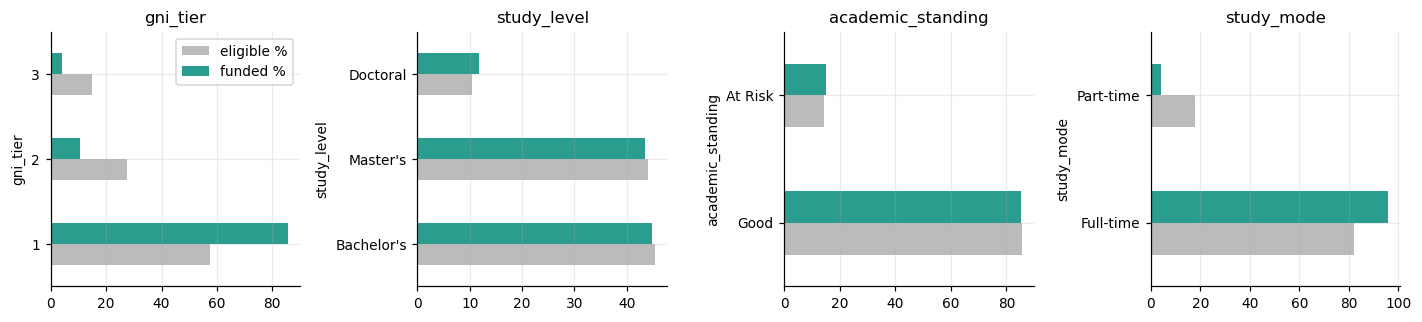

median shortfall ratio  funded: 0.80 | eligible not funded: 0.49


In [17]:
# Who is funded? Composition of the final list against the eligible pool
def share(col):
    e = df.loc[df.eligible, col].astype(str).value_counts(normalize=True).mul(100)
    f = df.loc[df.award > 0, col].astype(str).value_counts(normalize=True).mul(100)
    return pd.DataFrame({"eligible %": e, "funded %": f}).fillna(0).round(1)
fig, axs = plt.subplots(1, 4, figsize=(13, 3))
for ax, col in zip(axs, ["gni_tier", "study_level", "academic_standing", "study_mode"]):
    share(col).plot.barh(ax=ax, color=["#bbbbbb", "#2a9d8f"], legend=(col == "gni_tier"))
    ax.set_title(col)
plt.tight_layout(); plt.show()
print("median shortfall ratio  funded: %.2f | eligible not funded: %.2f" % (
    df.loc[df.award > 0, "shortfall_ratio"].median(), df.loc[df.eligible & (df.award == 0), "shortfall_ratio"].median()))

**Final list: 154 awards, CHF 500,000** (mean CHF 3,247, 55% of each request). The median shortfall ratio is 0.80 among recipients against 0.49 among eligible applicants not funded. By GNI tier: 132 / 16 / 6 (tiers 1/2/3), from an eligible pool of 230 / 111 / 60. By level, the list is close to the eligible pool (69 Bachelor's, 67 Master's, 18 Doctoral). 23 recipients have GPAs below 2.5: our profile lowers their priority but does not exclude them. 12 awards are conditional on a pending permit.

In [18]:
# Output files: the full decision path (all 500) and the final allocation (funded only)
df["status"] = np.select([df.award > 0, ~df.eligible], [np.where(df.conditional, "funded (conditional)", "funded"),
                         "not eligible"], "eligible, not funded")
df["reason"] = np.select([df.award > 0, ~df.eligible], ["rank " + df.funding_rank.astype("Int64").astype(str) + " by Gower distance " + df.gower.round(3).astype(str) + "; " + str(int(FRAC_FINAL * 100)) + "% of request", "failed: " + df[HARD].apply(lambda r: ", ".join(h for h in HARD if r[h].startswith("fail")), axis=1)], "eligible; distance " + df.gower.round(3).astype(str) + ", budget exhausted before this rank")
INPUTS = ["student_id", "study_level", "study_mode", "residency_permit", "gni_tier", "geographic_region", "gpa",
          "academic_standing", "need_2027", "shortfall_ratio", "family_household_income_chf", "savings_chf",
          "external_scholarship_amount_chf", "risk_count", "resil_count", "completion_year", "completion_month",
          "months_in_grant"]
STEPS = HARD + ["eligible", "conditional"] + ["gower_draft1", "gower", "gower_cluster", "award_draft1"] + ["request", "funding_rank", "award", "status", "reason"]
decision_progression = df[INPUTS + STEPS]
decision_progression.to_csv("decision_progression.csv", index=False)
final = decision_progression[decision_progression.award > 0].sort_values("funding_rank")
final.to_csv("final_allocation.csv", index=False)
print("decision_progression.csv:", decision_progression.shape, "| final_allocation.csv:", final.shape,
      f"| total CHF {final.award.sum():,.0f}")
final.head(8)

decision_progression.csv: (500, 36) | final_allocation.csv: (154, 36) | total CHF 500,000


,student_id,study_level,study_mode,residency_permit,gni_tier,geographic_region,gpa,academic_standing,need_2027,shortfall_ratio,family_household_income_chf,savings_chf,external_scholarship_amount_chf,risk_count,resil_count,...,H4,H5,H6,H7,eligible,conditional,gower_draft1,gower,gower_cluster,award_draft1,request,funding_rank,award,status,reason
STU000489,STU000489,Master's,Full-time,B,1,South Asia,2.90,Good,2240,0.925620,870,0,0,4,3,...,pass,pass,pass,pass (assumed),True,False,0.222105,0.096468,1.0,3276.0,5958.0,1.0,3276.0,funded,rank 1 by Gower distance 0.096; 55% of request
STU000274,STU000274,Bachelor's,Full-time,Pending,1,Sub-Saharan Africa,3.13,Good,1960,0.937799,540,2375,5151,4,3,...,pass,pass,pass,pass (assumed),True,True,0.186561,0.123099,1.0,4033.0,7333.0,2.0,4033.0,funded (conditional),rank 2 by Gower distance 0.123; 55% of request
STU000032,STU000032,Master's,Full-time,B,1,Middle East/North Africa,3.03,Good,1862,0.707447,1250,0,0,4,5,...,pass,pass,pass,pass (assumed),True,False,0.217800,0.134394,1.0,3276.0,5958.0,3.0,3276.0,funded,rank 3 by Gower distance 0.134; 55% of request
STU000024,STU000024,Bachelor's,Full-time,B,1,Middle East/North Africa,3.02,Good,2214,0.940527,550,0,0,2,3,...,pass,pass,pass,pass (assumed),True,False,0.213521,0.137811,1.0,4033.0,7333.0,4.0,4033.0,funded,rank 4 by Gower distance 0.138; 55% of request
STU000377,STU000377,Bachelor's,Full-time,Pending,1,Sub-Saharan Africa,3.07,Good,1645,0.747727,800,0,0,5,3,...,pass,pass,pass,pass (assumed),True,True,0.221691,0.150194,1.0,4033.0,7333.0,5.0,4033.0,funded (conditional),rank 5 by Gower distance 0.15; 55% of request
STU000335,STU000335,Doctoral,Full-time,Pending,1,South Asia,3.63,Good,2263,0.930127,840,7717,0,5,3,...,pass,pass,pass,pass (assumed),True,True,0.253872,0.154791,1.0,2520.0,4583.0,6.0,2520.0,funded (conditional),rank 6 by Gower distance 0.155; 55% of request
STU000380,STU000380,Bachelor's,Full-time,B,1,South Asia,2.95,Good,1682,0.903330,770,0,0,2,4,...,pass,pass,pass,pass (assumed),True,False,0.237709,0.171823,1.0,4033.0,7333.0,7.0,4033.0,funded,rank 7 by Gower distance 0.172; 55% of request
STU000366,STU000366,Bachelor's,Full-time,B,1,Sub-Saharan Africa,2.74,Good,1931,0.884158,890,0,7267,2,4,...,pass,pass,pass,pass (assumed),True,False,0.246997,0.172205,1.0,4033.0,7333.0,8.0,4033.0,funded,rank 8 by Gower distance 0.172; 55% of request


### 4.2 Which decisions are the model's, and which are ours

| Decision | Made by | How |
|---|---|---|
| Reference profile (the applicant the call most wants to reach) | Humans (us) | Step 3.1, from the call's criteria |
| Feature weights | Humans (us) | call's 40/25/20/10/5, split by us |
| Distance of every applicant to the profile, and between applicants | Model (a formula, not learnt) | weighted Gower |
| Structure of the pool | Model | average-linkage clustering, k by silhouette |
| GPA reference 3.0 (not 4.0) | Humans (us) | Step 3.1; effect checked in 3.3 |
| Progress measured within study level | Humans (us) | revised after the margin review (3.4, 4.1) |
| Number of awards (~150) and therefore the award fraction | Humans (us) | Step 1.3 and 4.1 |
| Permit C threshold CHF 5,000; GPA < 2.5 not excluding | Humans (us) | Step 1.1 |


### 4.3 Reproducibility

Deterministic: no random element except the weight perturbations in 3.3 (seed 2026). Specification in full: features,
weights and reference profile (3.1, revised in 4.1), Gower formula (`gower_to`, 3.1), clustering (average linkage on the pairwise
Gower matrix, k by silhouette over 2–10), award rule (4.1).

### 4.4 Summary of our decision path

1. 500 → **401 eligible** (76 no shortfall in the grant period; **37 Permit C with household ≥ CHF 5,000**, our strict reading). GPA < 2.5 is not excluding (81 applicants), only penalised.
2. Declared reference profile with 12 mixed-type features and the call's weights. Weighted Gower distance, implemented by hand.
3. Structure: no meaningful clusters (k = 2, one small better-resourced group). Sensitivity: robust to ±25% weight changes. The GPA reference (3.0 vs 4.0) swaps 12 awards.
4. Margin review revealed a **saturated progress term** (64% of applicants; 88% of Master's). Progress was re-measured within study level.
5. Award fraction set to reach ~150 awards: 55% of request. **Final: 154 awards, CHF 500,000.**

Output files: `decision_progression.csv` (all 500, both distances, draft-1 and final awards) and `final_allocation.csv`.